# ANALYSES MULTIVARIES DU DATASET KIDNEY DISEASE

## ETAPES 
* 1. Vérifier la pertinence de l'ACP * 
    . Examiner la matrice de Corrélation 
    . Effectuer le test de sphéricité de Bartlett et le KMO

* 2. Extraire les composantes 
    . Calcul des valeurs propres et vecteurs propres de la matrice de corrélation
    . Obtention des composantes principales et des coordonnées des individus 

* 3. Choisir le nombre d'axes à retenir 
    . Repérer le coude 
    . Critère de Kaiser
    . Pourcentage cumulé d'inertie expliquée 
    . Interprètabilité des axes

* 4. Interprèter les variables
    .Cercle des corrélations
    .Corrélations Variables-axes, contributions et qualité de représentations 
    .Donner un sens a chaque axe 
    
* 5. Interprèter les individus 
    .Nuage des individus dans les plans factoriels 
    .Contributions et cos² pour repérer les individus qui sont mal représentés.
    .Variables supplémentaires projetés sans influencer la construction des axes 

* 6. Clustering
    .Se baser sur du K-Means pour regrouper les individus présentant des caractéristiques communs 


* 7. Synthétiser et conclure 
    .Résumer la structure des données les oppositions et          regroupement observés 
    


In [1]:
# Imports
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns  
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity
from factor_analyzer.factor_analyzer import calculate_kmo
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score

In [2]:
data = pd.read_csv("../data/kidney_clean_imputed.csv")

### 1. Vérification de la pertinence de l'ACP 

* Matrice de correlation 


            id       age        bp        sg        al        su       bgr  \
id    1.000000 -0.184772 -0.245062  0.641239 -0.539518 -0.273881 -0.328965   
age  -0.184772  1.000000  0.157975 -0.203819  0.126455  0.212592  0.246562   
bp   -0.245062  0.157975  1.000000 -0.196083  0.186810  0.219682  0.153000   
sg    0.641239 -0.203819 -0.196083  1.000000 -0.478192 -0.289334 -0.326702   
al   -0.539518  0.126455  0.186810 -0.478192  1.000000  0.273013  0.354803   
su   -0.273881  0.212592  0.219682 -0.289334  0.273013  1.000000  0.749447   
bgr  -0.328965  0.246562  0.153000 -0.326702  0.354803  0.749447  1.000000   
bu   -0.311186  0.185237  0.199282 -0.336660  0.475426  0.140104  0.130936   
sc   -0.268262  0.127802  0.150658 -0.354112  0.296001  0.127647  0.033747   
sod   0.425272 -0.104891 -0.090576  0.404834 -0.466058 -0.141541 -0.267985   
pot  -0.040276  0.117732  0.094956  0.031166  0.115863  0.027977 -0.029954   
hemo  0.641556 -0.199780 -0.284754  0.591721 -0.635736 -0.208252

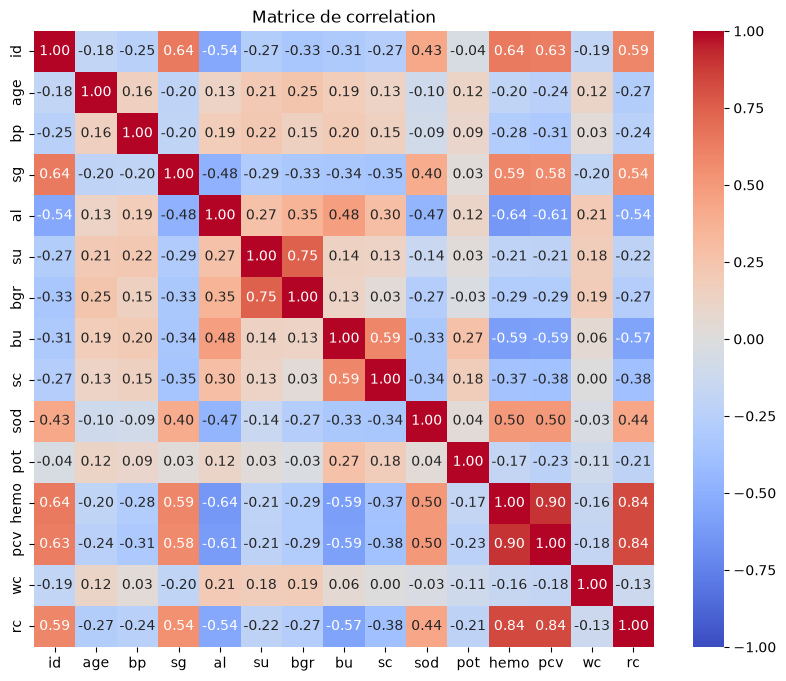

In [3]:

matrice_cor = data.corr(numeric_only=True)
print(matrice_cor)

plt.figure(figsize=(10,8))
sns.heatmap(
    matrice_cor,
    annot= True,
    fmt= ".2f",
    cmap= "coolwarm",
    vmin=-1,
    vmax= 1
)
plt.title("Matrice de correlation")
plt.show()

De l'analyse de cette matrice de correlation on remarque que : 
* il existe une forte correlation positive entre **hemo** et **pvc** (0,90), donc elles varient dans le meme sens 
* il existe une forte correlation entre **hemo** et **rc** (0,84) et entre **pvc** et **rc** (0,84) : on déduis donc que ces trois variables forment un bloc homogène liés aux globules rouge
* Plus la glycémie aléatoire bgr est élevée, plus le taux de sucre urinaire su l'est aussi: forte corrélation positive (0,75) .Mais elles sont faiblement correlées au reste des variables du dataset 
* les variables al, bu , sc sont associées positivement entres elles mais négativement a **hemo** , **pcv** , et **rc** 


On peut donc déduire comme première idée que : 
Notre premier axe opposera {**hemo**, **rc**, **pvc**} a {**al**, **bu**, **sc** }
et notre second axe sera constitué de {**bgr** , **sc**}


Aussi les correlations sont assez nombreuses pour justifier une ACP . Faisons une deuxième vérification avec Bartlett


### **Test de Bartlett**

H0: Les variables ne sont pas correlées entres elles



H1: il existe donc des corrélations entre les variables


**Le principe  est simple : comparé la matrice de correlation a la matrice identité** 

In [4]:
X = data[["age","bp","sg","al","su","bgr","bu","sc","sod","pot","hemo","pcv","wc","rc"]]

chi_square_value, p_value = calculate_bartlett_sphericity(X)

print("Statistique du test de Bartlett :", chi_square_value)
print("p-value :", p_value)

Statistique du test de Bartlett : 2795.260844438692
p-value : 0.0


 P-value = 0.0 d'ou p < 0,001
 Alors on rejette H0 au seuil de 5%  et on conclut que les variables sont significativement corrélées, ce qui justifie le recours à l'ACP.

* KMO

In [5]:
kmo_per_variable, kmo_total = calculate_kmo(X)

print("KMO global :", round(kmo_total, 3))
print(pd.Series(kmo_per_variable, index=X.columns).round(3))

KMO global : 0.843
age     0.852
bp      0.871
sg      0.926
al      0.937
su      0.637
bgr     0.667
bu      0.865
sc      0.755
sod     0.874
pot     0.648
hemo    0.861
pcv     0.862
wc      0.747
rc      0.928
dtype: float64


KMO global: 0,843 > 0,5
On en déduis donc qu'aucune variable n'est a retirer de l'analyse  car chaque variable partage suffisamment de variance commune avec les autres pour être conservée dans l'ACP

## **Extraction des variables**

* Calcul des vecteurs et valeurs propres: Direction d'un axe principal de l'ACP tel que pour un vecteur  v de matrice de corrélation Rv on a :


**Rv = ʎv** avec ʎ la valeur propre

      Valeur propre  % variance  % cumulé
CP1           5.252      37.515    37.515
CP2           1.726      12.326    49.841
CP3           1.209       8.635    58.476
CP4           0.963       6.881    65.358
CP5           0.883       6.306    71.663
CP6           0.842       6.016    77.680
CP7           0.814       5.816    83.495
CP8           0.577       4.122    87.617
CP9           0.514       3.675    91.292
CP10          0.451       3.223    94.515
CP11          0.295       2.106    96.621
CP12          0.215       1.533    98.154
CP13          0.168       1.202    99.356
CP14          0.090       0.644   100.000
        CP1    CP2    CP3    CP4    CP5    CP6    CP7    CP8    CP9   CP10  \
age   0.148  0.162  0.377  0.343  0.247 -0.517 -0.554 -0.141  0.055  0.160   
bp    0.158  0.061  0.338  0.147 -0.796 -0.230  0.282 -0.224 -0.077  0.025   
sg   -0.307 -0.094  0.225 -0.019  0.047  0.172  0.033 -0.529  0.570 -0.280   
al    0.323  0.029 -0.164 -0.041  0.022  0.251  0.057 -0.2

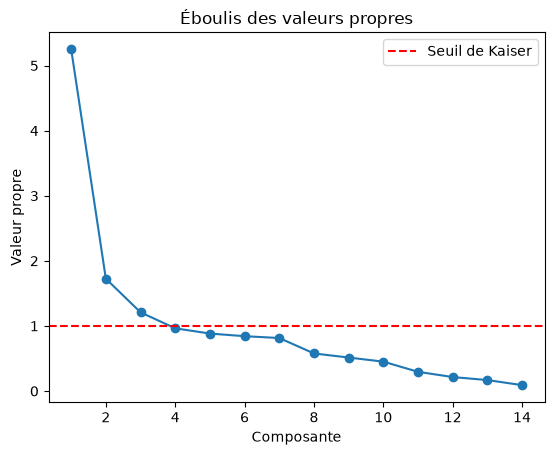

In [8]:
import numpy as np
import pandas as pd

variables = ["age","bp","sg","al","su","bgr","bu","sc","sod","pot","hemo","pcv","wc","rc"]
p = len(variables)
noms_cp = [f"CP{i+1}" for i in range(p)]

matrice_cor = data[["age","bp","sg","al","su","bgr","bu","sc","sod","pot","hemo","pcv","wc","rc"]].corr()
valeurs_propres, vecteurs_propres = np.linalg.eigh(matrice_cor)

# Tri décroissant
indices = np.argsort(valeurs_propres)[::-1]
valeurs_propres = valeurs_propres[indices]
vecteurs_propres = vecteurs_propres[:, indices]

# Tableau des valeurs propres
eig = pd.DataFrame({
    "Valeur propre": valeurs_propres,
    "% variance": valeurs_propres / valeurs_propres.sum() * 100,
    "% cumulé": np.cumsum(valeurs_propres) / valeurs_propres.sum() * 100
}, index=noms_cp)
print(eig.round(3))

# Vecteurs propres
vecteurs_df = pd.DataFrame(vecteurs_propres, index=variables, columns=noms_cp)
print(vecteurs_df.round(3))

# Corrélations variables-axes 
correlations = vecteurs_df * np.sqrt(valeurs_propres)
print(correlations.iloc[:, :4].round(3))

# Éboulis
import matplotlib.pyplot as plt
plt.plot(range(1, p+1), valeurs_propres, marker="o")
plt.axhline(1, color="red", linestyle="--", label="Seuil de Kaiser")
plt.xlabel("Composante"); plt.ylabel("Valeur propre")
plt.title("Éboulis des valeurs propres"); plt.legend()
plt.show()

En se basant sur le critère de Kaiser , on constate que 3 axes ont des valeurs propres  strictement supérieur a 1 . Il s'agit de CP1 , CP2 , et CP3 . CP4 quant a lui passe légèrement en dessous du seuil (0,96)donc il a été écarté de l'analyse.

On remarque donc que ces axes n'expliquent que 58,5% de variance .Cela est certe petit mais s'explique par les variables isolées (age, bp, pot, wc) qui ne se rattachent à aucun bloc et dispersent l'inertie sur beaucoup d'axes. Autrement dit , elles  sont faiblement corrélées aux autres et se projettent sur des axes d'ordre supérieur.

**Interpretation des axes**:
calcul des correlations variables-axes , la qualité de représentation(cos²) et les contributions 

In [9]:
corr = vecteurs_df * np.sqrt(valeurs_propres)  
cos2 = corr**2                                   
contrib = (vecteurs_df**2) * 100                 

print("Corrélations (CP1-CP3) :\n", corr.iloc[:, :3].round(3))
print("\nCos² (CP1-CP3) :\n", cos2.iloc[:, :3].round(3))
print("\nContributions % (CP1-CP3) :\n", contrib.iloc[:, :3].round(2))
print("\nQualité cumulée sur CP1-3 :\n", cos2.iloc[:, :3].sum(axis=1).round(3))

Corrélations (CP1-CP3) :
         CP1    CP2    CP3
age   0.338  0.213  0.415
bp    0.362  0.080  0.371
sg   -0.702 -0.123  0.248
al    0.741  0.038 -0.180
su    0.416  0.720  0.287
bgr   0.470  0.742  0.132
bu    0.700 -0.351  0.149
sc    0.539 -0.346  0.100
sod  -0.604  0.045  0.365
pot   0.217 -0.361  0.669
hemo -0.892  0.152  0.118
pcv  -0.897  0.155  0.053
wc    0.228  0.374 -0.275
rc   -0.852  0.160  0.018

Cos² (CP1-CP3) :
         CP1    CP2    CP3
age   0.114  0.045  0.172
bp    0.131  0.006  0.138
sg    0.494  0.015  0.061
al    0.549  0.001  0.033
su    0.173  0.518  0.082
bgr   0.221  0.551  0.018
bu    0.491  0.124  0.022
sc    0.290  0.120  0.010
sod   0.365  0.002  0.133
pot   0.047  0.130  0.447
hemo  0.796  0.023  0.014
pcv   0.804  0.024  0.003
wc    0.052  0.140  0.076
rc    0.726  0.025  0.000

Contributions % (CP1-CP3) :
         CP1    CP2    CP3
age    2.18   2.62  14.24
bp     2.50   0.37  11.41
sg     9.40   0.88   5.08
al    10.46   0.08   2.69
su     3.30  30

**Seuil indicatif utilisé** : une corrélation variable-axe est jugée forte au-delà de |0,6| environ, moyenne entre 0,4 et 0,6. Les signes sont arbitraires, seules les oppositions comptent

En se basant sur cet seuil on remarque que :
* l'axe CP1 est dominé négativement avec **pcv** (-0,897), **hemo** (-0,892), **rc** (-0,852), **sg** (-0,702), **sod** (-0,604), et positivement par **al** (0,741), **bu** (0,700), **sc** (0,539). Mais les contributions les plus fortes sont celles du bloc négatif . On conclut donc que l'axe **CP1** oppose les patients avec une bonne formule sanguine, une densité urinaire et une natrémie élevées à ceux avec albuminurie, urée et créatinine élevées. Cela confirme l'hypothèse faite à partir de la matrice de corrélation.


* l'axe CP2 est dominé postivement par **bgr** (0,742) et **su** (0,720), qui contribuent à eux deux à environ 62 % de l'axe.Cet axe correspond donc aux patients ayant un taux de glycémie élevée etun taux de sucre urinaires élevés 


* l'axe CP3 est dominé positivement par pot (0,669, soit environ 37 % de la contribution), puis moyennement par age (0,415), bp (0,371) et sod (0,365) et négativement par wc (-0,275): faible


### **cercle des corrélations et individus**

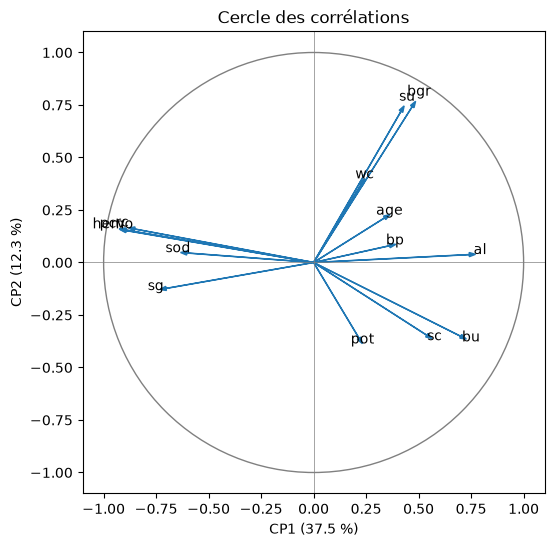

In [10]:

a, b = 0, 1
fig, ax = plt.subplots(figsize=(6,6))
ax.add_patch(plt.Circle((0,0), 1, fill=False, color="gray"))
for v in variables:
    x, y = corr.loc[v].iloc[a], corr.loc[v].iloc[b]
    ax.arrow(0, 0, x, y, head_width=0.02, color="tab:blue")
    ax.text(x*1.07, y*1.07, v, ha="center")
ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
ax.set_xlim(-1.1,1.1); ax.set_ylim(-1.1,1.1); ax.set_aspect("equal")
ax.set_xlabel(f"CP{a+1} ({eig.iloc[a,1]:.1f} %)"); ax.set_ylabel(f"CP{b+1} ({eig.iloc[b,1]:.1f} %)")
ax.set_title("Cercle des corrélations")
plt.show()
X_scaled = (X - X.mean()) / X.std(ddof=0)
# Coordonnées des individus (X_scaled = X centré-réduit, sans NaN)
coord_ind = X_scaled @ vecteurs_propres

### Cercle des corrélations des axes 1 et 2
* Les variables hemo, pcv et rc sont quasi confondues et proches du cercle : elles sont très fortement corrélées entre elles et très bien représentées. Elles s'opposent à al, bu et sc, ce qui structure l'axe 1 (gradient de gravité). sg et sod se placent du côté de hemo, pcv et rc.
* su et bgr forment un second groupe, bien représenté, qui définit l'axe 2 (glycémie). Ce groupe est quasi orthogonal au premier : la glycémie est peu liée au gradient de gravité.
* Les variables age, bp, wc et pot ont des flèches courtes : elles sont mal représentées dans ce plan et ne sont pas interprétées. pot s'exprime sur l'axe 3.

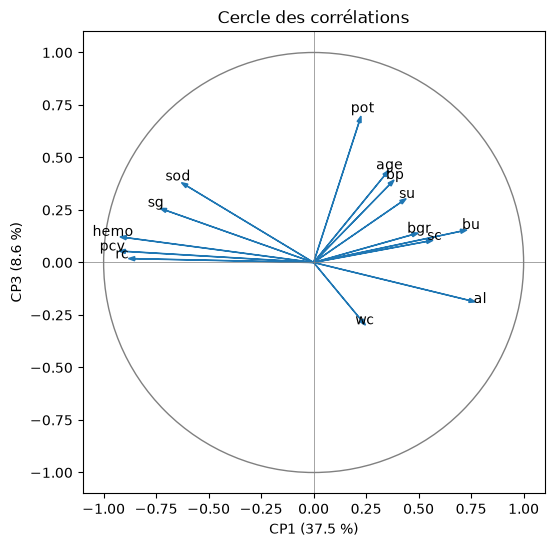

In [11]:

a, b = 0, 2
fig, ax = plt.subplots(figsize=(6,6))
ax.add_patch(plt.Circle((0,0), 1, fill=False, color="gray"))
for v in variables:
    x, y = corr.loc[v].iloc[a], corr.loc[v].iloc[b]
    ax.arrow(0, 0, x, y, head_width=0.02, color="tab:blue")
    ax.text(x*1.07, y*1.07, v, ha="center")
ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
ax.set_xlim(-1.1,1.1); ax.set_ylim(-1.1,1.1); ax.set_aspect("equal")
ax.set_xlabel(f"CP{a+1} ({eig.iloc[a,1]:.1f} %)"); ax.set_ylabel(f"CP{b+1} ({eig.iloc[b,1]:.1f} %)")
ax.set_title("Cercle des corrélations")
plt.show()
X_scaled = (X - X.mean()) / X.std(ddof=0)
# Coordonnées des individus (X_scaled = X centré-réduit, sans NaN)
coord_ind = X_scaled @ vecteurs_propres

### Cercle des corrélations plan 1-3, 
* L'axe 3 est principalement porté par le potassium (pot, r = 0,67), mal représenté dans le plan 1-2. L'âge, la pression artérielle et le sodium y contribuent de façon plus modérée.
* L'opposition de l'axe 1 (hemo, pcv, rc, sg, sod contre al, bu, sc) se retrouve inchangée, ce qui confirme sa robustesse.
* Les variables wc et bp restent peu représentées et ne sont pas interprétées.

### Nuage des individus

In [12]:
coord_df = pd.DataFrame(X_scaled.values @ vecteurs_propres, index=X.index, columns=noms_cp)

print(coord_df.var(ddof=0).iloc[:3].round(3).tolist())

[5.252, 1.726, 1.209]


In [13]:
# Alignement avec les individus réellement utilisés dans l'ACP
classif = data.loc[X.index, "classification"].astype(str).str.strip()   # strip : enlève d'éventuels espaces/tabulations ("ckd\t")
print(classif.value_counts())

classification
ckd       250
notckd    150
Name: count, dtype: int64


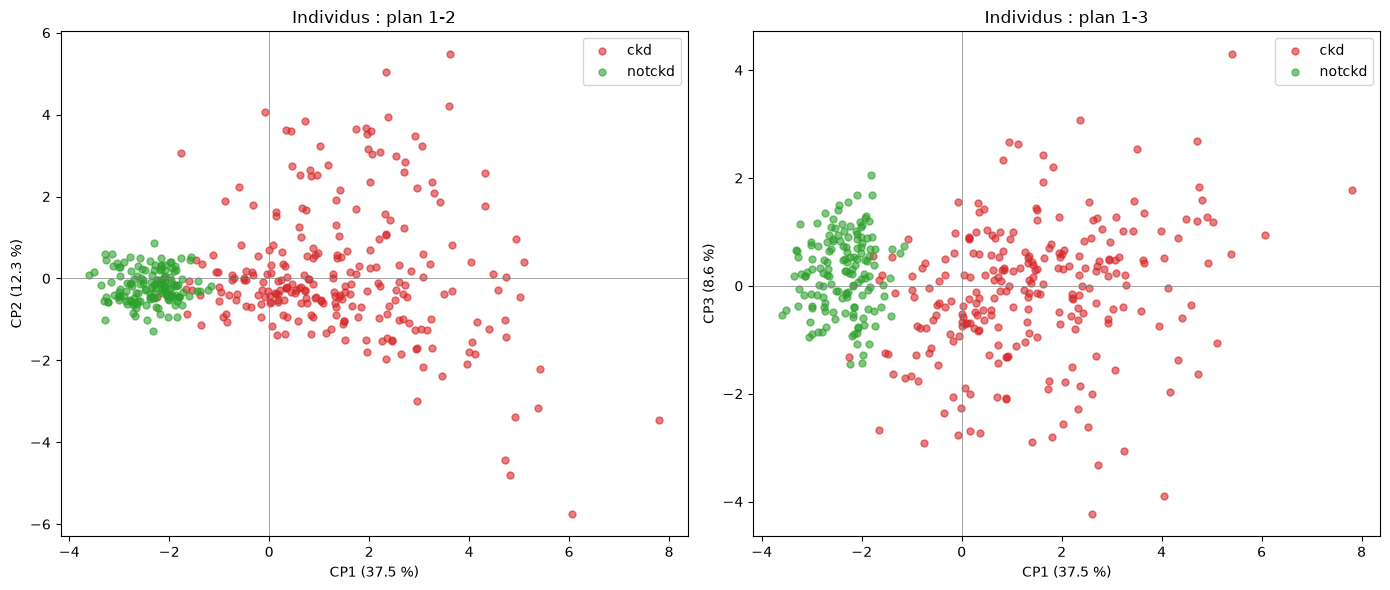

In [14]:
couleurs = {g: c for g, c in zip(classif.unique(), ["tab:red", "tab:green"])}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (a, b) in zip(axes, [(0, 1), (0, 2)]):
    for g in classif.unique():
        m = classif == g
        ax.scatter(coord_df.iloc[:, a][m], coord_df.iloc[:, b][m],
                   label=g, alpha=.6, s=25, color=couleurs[g])
    ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
    ax.set_xlabel(f"CP{a+1} ({eig.iloc[a,1]:.1f} %)")
    ax.set_ylabel(f"CP{b+1} ({eig.iloc[b,1]:.1f} %)")
    ax.set_title(f"Individus : plan {a+1}-{b+1}")
    ax.legend()
plt.tight_layout()
plt.show()

                  CP1    CP2    CP3
classification                     
ckd             1.422  0.115 -0.144
notckd         -2.369 -0.192  0.239


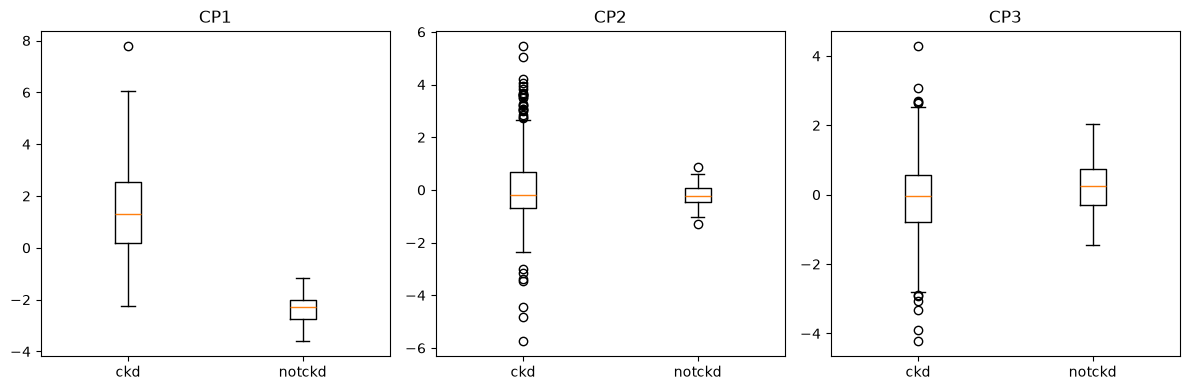

CP1 : eta² = 0.641
CP2 : eta² = 0.013
CP3 : eta² = 0.028


In [15]:
# Moyenne des coordonnées par groupe
print(coord_df.iloc[:, :3].groupby(classif).mean().round(3))

# Boxplots des 3 premiers axes selon le groupe
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
groupes = list(classif.unique())

for i, ax in enumerate(axes):
    ax.boxplot([coord_df.iloc[:, i][classif == g] for g in groupes],
               tick_labels=groupes)
    ax.set_title(f"CP{i+1}")
plt.tight_layout()
plt.show()

# Rapport de corrélation (eta²) : part de la variance de chaque axe expliquée par le groupe
for i in range(3):
    y = coord_df.iloc[:, i]
    eta2 = 1 - sum(((y[classif == g] - y[classif == g].mean())**2).sum()
                   for g in classif.unique()) / ((y - y.mean())**2).sum()
    print(f"CP{i+1} : eta² = {eta2:.3f}")

### **Clusters**

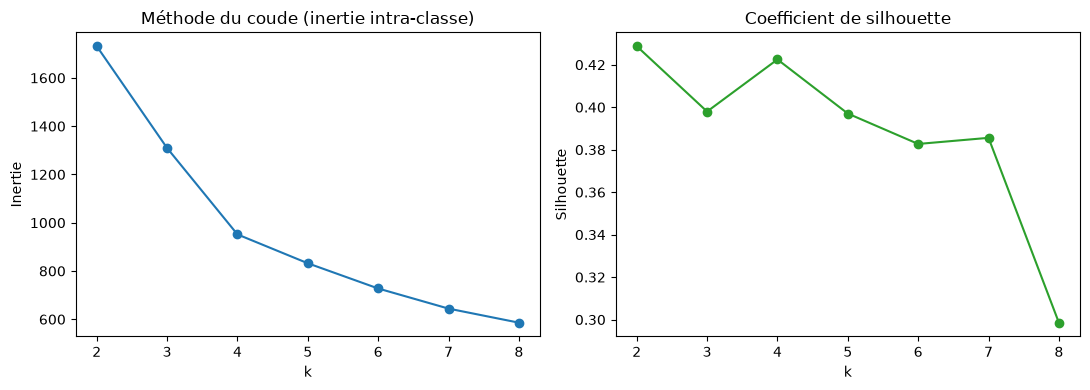

   k  inertie  silhouette
0  2   1731.5       0.429
1  3   1309.5       0.398
2  4    951.5       0.422
3  5    832.0       0.397
4  6    727.5       0.383
5  7    644.1       0.386
6  8    585.9       0.299


In [16]:
Z = coord_df.iloc[:, :3]

ks = range(2, 9)
inerties, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(Z)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(Z, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inerties, marker="o")
axes[0].set_title("Méthode du coude (inertie intra-classe)")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertie")
axes[1].plot(ks, silhouettes, marker="o", color="tab:green")
axes[1].set_title("Coefficient de silhouette")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

print(pd.DataFrame({"k": list(ks), "inertie": np.round(inerties, 1),
                    "silhouette": np.round(silhouettes, 3)}))



In [17]:

K = 2
km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(Z)
clusters = pd.Series(km.labels_, index=Z.index, name="cluster")

print(clusters.value_counts().sort_index())
print("\nTableau croisé clusters / diagnostic :")
print(pd.crosstab(clusters, classif))
print("\nEn % par cluster :")
print(pd.crosstab(clusters, classif, normalize="index").round(3) * 100)

print("\nIndice de Rand ajusté :", round(adjusted_rand_score(classif, clusters), 3))

cluster
0    206
1    194
Name: count, dtype: int64

Tableau croisé clusters / diagnostic :
classification  ckd  notckd
cluster                    
0               206       0
1                44     150

En % par cluster :
classification    ckd  notckd
cluster                      
0               100.0     0.0
1                22.7    77.3

Indice de Rand ajusté : 0.607


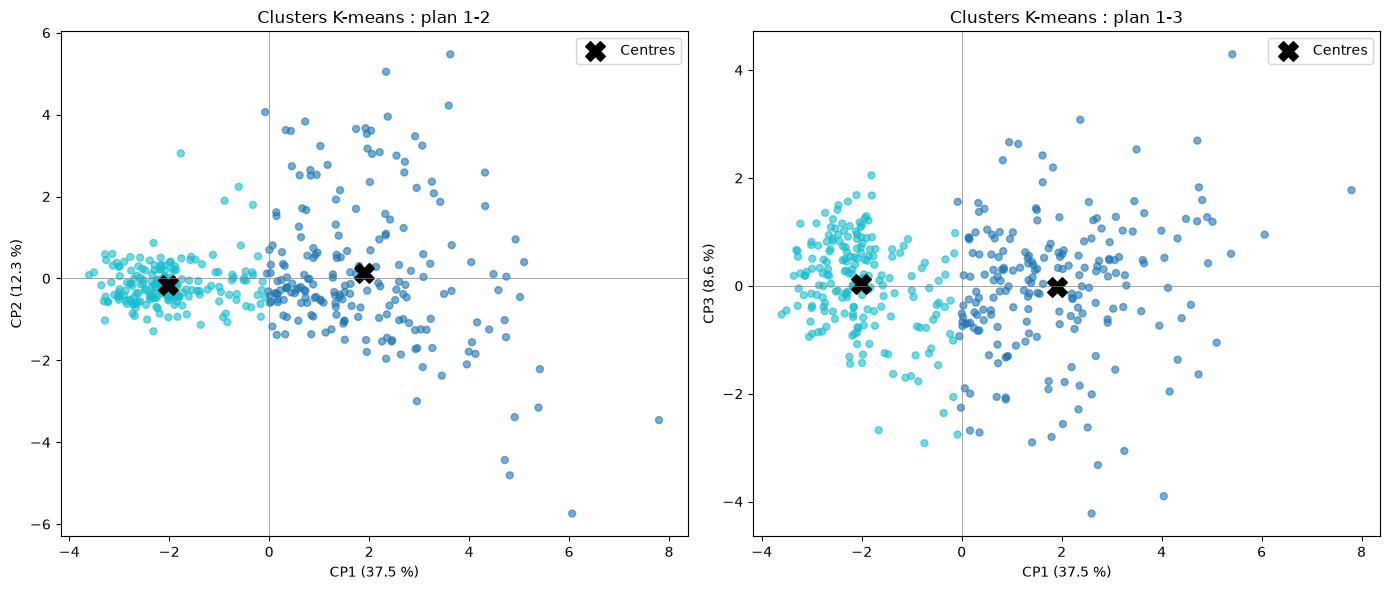

cluster        0        1
age        57.88    44.74
bp         80.36    72.24
sg          1.01     1.02
al          1.90     0.20
su          0.86     0.04
bgr       182.49   112.23
bu         81.60    31.56
sc          4.92     1.07
sod       134.38   141.11
pot         4.47     4.28
hemo       10.35    14.66
pcv        31.73    44.94
wc       9026.96  7808.52
rc          3.89     5.25
cluster     0     1
age      0.38 -0.40
bp       0.29 -0.31
sg      -0.64  0.68
al       0.63 -0.67
su       0.37 -0.40
bgr      0.44 -0.47
bu       0.49 -0.52
sc       0.33 -0.35
sod     -0.50  0.53
pot      0.14 -0.15
hemo    -0.75  0.80
pcv     -0.75  0.79
wc       0.23 -0.25
rc      -0.70  0.75
           CP1    CP2    CP3
cluster                     
0        1.901  0.143 -0.028
1       -2.018 -0.152  0.029


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (a, b) in zip(axes, [(0, 1), (0, 2)]):
    sc = ax.scatter(Z.iloc[:, a], Z.iloc[:, b], c=clusters, cmap="tab10", alpha=.6, s=25)
    ax.scatter(km.cluster_centers_[:, a], km.cluster_centers_[:, b],
               marker="X", s=200, c="black", label="Centres")
    ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
    ax.set_xlabel(f"CP{a+1} ({eig.iloc[a,1]:.1f} %)")
    ax.set_ylabel(f"CP{b+1} ({eig.iloc[b,1]:.1f} %)")
    ax.set_title(f"Clusters K-means : plan {a+1}-{b+1}")
    ax.legend()
plt.tight_layout(); plt.show()


# Profil moyen sur les variables d'origine
profil = X.groupby(clusters).mean().round(2)
print(profil.T)

# Profil en écarts réduits (plus lisible : positif = au-dessus de la moyenne générale)
profil_z = X_scaled.groupby(clusters).mean().round(2)
print(profil_z.T)

# Position sur les axes
print(Z.groupby(clusters).mean().round(3))

**Les clusters ont été construits sans utiliser `classification`** (K = 2 sur les 3 premiers axes, silhouette maximale : 0,43). Leur comparaison avec le diagnostic sert de validation : le cluster 0 compte 100 % de `ckd`, le cluster 1 compte 77,3 % de `notckd` (indice de Rand ajusté = 0,607 ; concordance de 89 %).

*Limite :* `classification` a participé à l'estimation de 781 valeurs imputées, donc cette validation n'est pas totalement indépendante. Avec une imputation sans la classe, la concordance est de 84,2 % et l'indice de Rand de 0,468 : le résultat reste net, mais moins fort.

**Profil des clusters**

| | Cluster 0 (206 patients) | Cluster 1 (194 patients) |
|---|---|---|
| Hémoglobine / hématocrite / globules rouges | 10,4 / 31,7 / 3,9 | 14,7 / 44,9 / 5,25 |
| Albumine / urée / créatinine | 1,90 / 81,6 / 4,9 | 0,20 / 31,6 / 1,07 |
| Glycémie (`bgr`) | 182 | 112 |

Les deux groupes s'opposent sur le gradient de gravité de l'axe 1. La glycémie est aussi plus élevée dans le cluster 0, mais elle forme un axe distinct (axe 2) ; le potassium (axe 3) ne structure pas la partition.

**Tableau croisé**

* Cluster 0 : uniquement des `ckd`, aucun `notckd` classé comme malade.
* Cluster 1 : les 150 `notckd` et 44 `ckd`. Ainsi 206 `ckd` sur 250 (82,4 %) sont isolés, et 17,6 % sont mélangés aux sujets sains.
* Explications plausibles, non testées : atteinte débutante (profil proche de la normale), tailles équilibrées imposées par K-means (206 / 194 contre 250 / 150), continuum entre sain et malade (silhouette modérée).

**Conclusion**

* L'axe 1 est un gradient de gravité : la partition, dominée par cet axe, retrouve 89 % du diagnostic (84 % avec une imputation sans la classe).
* Variables clés : hémoglobine, hématocrite, globules rouges, densité urinaire et sodium (côté préservé) ; albumine, urée et créatinine (côté atteint).
* Le regroupement repère bien les cas avérés (aucun faux malade), mais moins les formes légères (17,6 % de `ckd` non isolés). Le passage de sain à malade ressemble à un continuum plutôt qu'à deux populations distinctes.